In [ ]:
import numpy.random as rnd
import numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt
import scipy as sp
from scipy.stats import norm
import pandas_datareader as pd_data
from pandas_datareader import data as pdr
from datetime import datetime
from scipy.interpolate import interp1d 
# from scipy import arange, array, exp
from scipy.optimize import brentq
from scipy.interpolate import griddata
import datacleaning as dc
from opengreeks import black76
import os
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display
from mpl_toolkits.mplot3d import Axes3D

In [2]:
def Black76_OptionPrice(St,tau,F,K,dir,sigma):
    """
    St: current asset price (at time t)
    tau: time to expiry of the option
    F: forward price
    K: strike
    sigma: volatility
    ***all of the above can be both vectors and scalars***
    returns CALL PRICE(s) using the Black-76 formula
    """
    efact = F/St
    #delta of the option
    d1 = (np.log(F/K)+tau*0.5*sigma*sigma)/(sigma*np.sqrt(tau))
    d2 = d1-sigma*np.sqrt(tau)
    price = efact*(F*norm.cdf(d1)-K*norm.cdf(d2))
    if dir == 'CE':
        price = efact*(F*norm.cdf(d1)-K*norm.cdf(d2))
    elif dir == 'PE': 
        price = efact*(-F*norm.cdf(-d1)+K*norm.cdf(-d2))
    return price

def BS_OptionPrice(St,tau,r,K,dir,sigma):
    """
    St: current asset price (at time t)
    tau: time to expiry of the option
    r: risk-free interest rate
    K: strike
    sigma: volatility
    ***all of the above can be both vectors and scalars***
    returns CALL PRICE(s) using the Black-Scholes formula
    """
    #delta
    d1 = (np.log(St/K)+tau*(r+0.5*sigma*sigma))/(sigma*np.sqrt(tau))
    d2 = d1-sigma*np.sqrt(tau)
    if dir == 'CE':
        price = St*norm.cdf(d1)-K*norm.cdf(d2)*np.exp(-r*tau)
    elif dir == 'PE': 
        price = K*norm.cdf(-d2)*np.exp(-r*tau) - St*norm.cdf(-d1)

    return price

#Converting from K,T to m,tau
def K_T_to_mu_tau(K,T,St,t):
    return K/St,T-t
def mu_tau_to_K_T(mu,tau,St,t):
    return mu*St,tau+t

In [3]:
# %load_ext autoreload
# %autoreload 2

In [4]:
df_niftyoptions= pd.read_csv('data/niftyoptions_df.csv')
df_niftyspot = pd.read_csv('data/nifty_close.csv')

niftyoptions_df, niftyspot_df, spot, observation_dates = dc.optiondata_transform(df_niftyoptions, df_niftyspot)
datapath = 'data/datapath.csv'

def create_data(
    observation_dates,
    niftyoptions_df,
    niftyspot_df,
    m_grid=None,
    tau_days=None,
    datapath=datapath
):
    """
    datapath: Option-level data with calculated implied volatility.
    Parameters
    ----------
    observation_dates : iterable Trading observation_dates to process.
    niftyoptions_df : pd.DataFrame Preprocessed NIFTY option data.
    niftyspot_df : pd.DataFrame NIFTY spot data.
    m_grid : array-like Fixed moneyness grid.
    tau_days : array-like Fixed maturity grid in calendar days.
    datapath : str Output path for option-level data.
    surfacepath : str Output path for flattened surfaces.
    """

    if m_grid is None:
        m_grid = np.linspace(0.6, 1.4, 10)

    if tau_days is None:
        tau_days = np.array([7, 14, 30, 60,90, 180, 270, 365])

    tau_grid = np.asarray(tau_days) / 365.0

    data_list = []
    surface_list = []

    for date in observation_dates:

        subset_df, r1 = dc.data_day(date,niftyoptions_df,niftyspot_df)
        call_df = subset_df[subset_df["option_type"] == "CE"].copy()
        put_df = subset_df[subset_df["option_type"] == "PE"].copy()

        def solve_iv(row):
            F = row["spot"]
            St = row['spot']
            tau = row["ttm"]
            K = row["strike"]
            market_price = row["mid_price"]
            dir = row["option_type"]
            r = row['r']

            if (pd.isna(St) or pd.isna(tau) or pd.isna(K) or pd.isna(market_price)):
                return np.nan

            if St <= 0 or tau <= 0 or market_price <= 0:
                return np.nan

            def objective(sigma):
                model_price = Black76_OptionPrice(St,tau,F,K,dir,sigma)
                return model_price - market_price

            try:
                return brentq(objective, 1e-6, 5.0)
            except ValueError:
                return np.nan

        call_df["iv"] = call_df.apply( solve_iv, axis=1)
        call_df = call_df[call_df["iv"].notna()].copy()
        call_df = call_df[(call_df["iv"] > 0) & (call_df["iv"] < 5)].copy()
        data_list.append(call_df)

        put_df["iv"] = put_df.apply( solve_iv, axis=1)
        put_df = put_df[put_df["iv"].notna()].copy()
        put_df = put_df[(put_df["iv"] > 0) & (put_df["iv"] < 5)].copy()
        data_list.append(put_df)

    if len(data_list) > 0:
        data_output = pd.concat(data_list,ignore_index=True)
    else:
        data_output = pd.DataFrame()

    data_output.to_csv(datapath,index=False)
    print(f"datapath saved to: {datapath}")
    print(f"datapath shape: {data_output.shape}")

    return data_output

In [5]:
# subset_df, r = dc.data_day(observation_dates[0],niftyoptions_df,niftyspot_df)

In [6]:
# if os.path.exists('data/nifty_df.parquet') and False:
if os.path.exists('data/nifty_df.parquet'):
    nifty_df = pd.read_parquet('data/nifty_df.parquet')    
else:
    nifty_df = create_data(observation_dates,niftyoptions_df,niftyspot_df)
    nifty_df.to_parquet('data/nifty_df.parquet', index = False)

datapath saved to: data/datapath.csv
datapath shape: (481009, 17)


In [7]:
greek_functions = {
    "delta": black76.delta,
    "gamma": black76.gamma,
    "vega": black76.vega,
    "theta": black76.theta,
    "rho": black76.rho,
    "vanna": black76.vanna,
    "charm": black76.charm,
    "vomma": black76.vomma,
    "speed": black76.speed,
    "zomma": black76.zomma,
    "color": black76.color,
    "veta": black76.veta,
    "ultima": black76.ultima,
    "dual_delta": black76.dual_delta,
    "dual_gamma": black76.dual_gamma,
}


def calculate_greeks(row):
    F = float(row["spot"])
    K = float(row["strike"])
    t = float(row["ttm"])
    RATE = float(row["r"])
    price = float(row["close"])

    flag = {"CE": "c", "PE": "p"}.get(str(row["option_type"]).upper())

    result = {
        "implied_volatility": np.nan,
        "model_price": np.nan,
        "greek_error": None,
    }
    
    if flag is None or not all(
        np.isfinite(x) for x in [F, K, t, price]
    ) or F <= 0 or K <= 0 or t <= 0 or price <= 0:
        result["greek_error"] = "Invalid input"
        return pd.Series(result)

    try:
        iv = black76.implied_volatility(price, F, K, RATE, t, flag)
        if not np.isfinite(iv) or iv <= 0:
            raise ValueError("Invalid implied volatility")

        result["implied_volatility"] = iv
        result["model_price"] = black76.black(flag, F, K, t, RATE, iv)

        for name, func in greek_functions.items():
            result[name] = func(flag, F, K, t, RATE, iv)

    except Exception as exc:
        result["greek_error"] = str(exc)
    return pd.Series(result)

In [ ]:
# if os.path.exists('data/df_with_greeks.parquet') and False:
if os.path.exists('data/df_with_greeks.parquet'):
    df_with_greeks = pd.read_parquet('data/df_with_greeks.parquet')    
else:
    greek_columns = nifty_df.apply(calculate_greeks, axis=1)

    df_with_greeks = pd.concat(
        [nifty_df.reset_index(drop=True),
        greek_columns.reset_index(drop=True)],
        axis=1,
    )
    df_with_greeks.to_parquet('data/df_with_greeks.parquet', index = False)

In [9]:
nifty_df[(nifty_df['date'] == '2025-01-01')]

,index,date,timestamp,expiry,strike,option_type,close,date_dt,exdate_dt,time_to_expiry,days_to_exp,ttm,spot,moneyness,mid_price,r,iv
0,0,2025-01-01,2025-01-01,2025-01-30,26150.0,CE,8.10,2025-01-01,2025-01-30,29 days,29,0.079452,23742.9,1.101382,8.10,0.099836,0.165307
1,2,2025-01-01,2025-01-01,2025-02-27,22400.0,CE,2070.15,2025-01-01,2025-02-27,57 days,57,0.156164,23742.9,0.943440,2070.15,0.099836,0.354759
2,5,2025-01-01,2025-01-01,2025-01-02,25150.0,CE,0.80,2025-01-01,2025-01-02,1 days,1,0.002740,23742.9,1.059264,0.80,0.099836,0.423514
3,6,2025-01-01,2025-01-01,2025-02-27,25150.0,CE,109.05,2025-01-01,2025-02-27,57 days,57,0.156164,23742.9,1.059264,109.05,0.099836,0.142166
4,8,2025-01-01,2025-01-01,2025-01-16,26450.0,CE,3.15,2025-01-01,2025-01-16,15 days,15,0.041096,23742.9,1.114017,3.15,0.099836,0.222651
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1239,1549,2025-01-01,2025-01-01,2025-01-02,25150.0,PE,1533.35,2025-01-01,2025-01-02,1 days,1,0.002740,23742.9,1.059264,1533.35,0.099836,1.128881
1240,1550,2025-01-01,2025-01-01,2025-01-16,22400.0,PE,13.35,2025-01-01,2025-01-16,15 days,15,0.041096,23742.9,0.943440,13.35,0.099836,0.166404
1241,1557,2025-01-01,2025-01-01,2028-06-29,20000.0,PE,400.00,2025-01-01,2028-06-29,1275 days,1275,3.493151,23742.9,0.842357,400.00,0.099836,0.100495
1242,1559,2025-01-01,2025-01-01,2029-12-27,20000.0,PE,202.30,2025-01-01,2029-12-27,1821 days,1821,4.989041,23742.9,0.842357,202.30,0.099836,0.066866


In [10]:
nifty_df[(nifty_df['date'] == '2025-01-01')&(nifty_df['days_to_exp']==15)& (nifty_df['option_type'] == 'CE')].sort_values('strike')

,index,date,timestamp,expiry,strike,option_type,close,date_dt,exdate_dt,time_to_expiry,days_to_exp,ttm,spot,moneyness,mid_price,r,iv
612,1283,2025-01-01,2025-01-01,2025-01-16,21850.0,CE,2853.60,2025-01-01,2025-01-16,15 days,15,0.041096,23742.9,0.920275,2853.60,0.099836,0.949251
369,775,2025-01-01,2025-01-01,2025-01-16,21900.0,CE,2804.35,2025-01-01,2025-01-16,15 days,15,0.041096,23742.9,0.922381,2804.35,0.099836,0.938654
113,219,2025-01-01,2025-01-01,2025-01-16,21950.0,CE,2755.15,2025-01-01,2025-01-16,15 days,15,0.041096,23742.9,0.924487,2755.15,0.099836,0.928065
424,902,2025-01-01,2025-01-01,2025-01-16,22000.0,CE,2706.05,2025-01-01,2025-01-16,15 days,15,0.041096,23742.9,0.926593,2706.05,0.099836,0.917509
307,633,2025-01-01,2025-01-01,2025-01-16,22050.0,CE,2656.95,2025-01-01,2025-01-16,15 days,15,0.041096,23742.9,0.928699,2656.95,0.099836,0.906927
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
392,831,2025-01-01,2025-01-01,2025-01-16,26300.0,CE,2.70,2025-01-01,2025-01-16,15 days,15,0.041096,23742.9,1.107700,2.70,0.099836,0.208457
324,679,2025-01-01,2025-01-01,2025-01-16,26350.0,CE,2.25,2025-01-01,2025-01-16,15 days,15,0.041096,23742.9,1.109805,2.25,0.099836,0.207340
464,984,2025-01-01,2025-01-01,2025-01-16,26400.0,CE,2.65,2025-01-01,2025-01-16,15 days,15,0.041096,23742.9,1.111911,2.65,0.099836,0.214725
4,8,2025-01-01,2025-01-01,2025-01-16,26450.0,CE,3.15,2025-01-01,2025-01-16,15 days,15,0.041096,23742.9,1.114017,3.15,0.099836,0.222651


In [11]:
df_with_greeks
df_with_greeks[(df_with_greeks['date'] == '2025-01-01')&(df_with_greeks['days_to_exp']==15)& (df_with_greeks['option_type'] == 'CE')][list(nifty_df.columns) + ['delta']].sort_values('strike')


,index,date,timestamp,expiry,strike,option_type,close,date_dt,exdate_dt,time_to_expiry,days_to_exp,ttm,spot,moneyness,mid_price,r,iv,delta
612,1283,2025-01-01,2025-01-01,2025-01-16,21850.0,CE,2853.60,2025-01-01,2025-01-16,15 days,15,0.041096,23742.9,0.920275,2853.60,0.099836,0.949251,0.697517
369,775,2025-01-01,2025-01-01,2025-01-16,21900.0,CE,2804.35,2025-01-01,2025-01-16,15 days,15,0.041096,23742.9,0.922381,2804.35,0.099836,0.938654,0.694693
113,219,2025-01-01,2025-01-01,2025-01-16,21950.0,CE,2755.15,2025-01-01,2025-01-16,15 days,15,0.041096,23742.9,0.924487,2755.15,0.099836,0.928065,0.691809
424,902,2025-01-01,2025-01-01,2025-01-16,22000.0,CE,2706.05,2025-01-01,2025-01-16,15 days,15,0.041096,23742.9,0.926593,2706.05,0.099836,0.917509,0.688860
307,633,2025-01-01,2025-01-01,2025-01-16,22050.0,CE,2656.95,2025-01-01,2025-01-16,15 days,15,0.041096,23742.9,0.928699,2656.95,0.099836,0.906927,0.685850
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
392,831,2025-01-01,2025-01-01,2025-01-16,26300.0,CE,2.70,2025-01-01,2025-01-16,15 days,15,0.041096,23742.9,1.107700,2.70,0.099836,0.208457,0.008206
324,679,2025-01-01,2025-01-01,2025-01-16,26350.0,CE,2.25,2025-01-01,2025-01-16,15 days,15,0.041096,23742.9,1.109805,2.25,0.099836,0.207340,0.006986
464,984,2025-01-01,2025-01-01,2025-01-16,26400.0,CE,2.65,2025-01-01,2025-01-16,15 days,15,0.041096,23742.9,1.111911,2.65,0.099836,0.214725,0.007856
4,8,2025-01-01,2025-01-01,2025-01-16,26450.0,CE,3.15,2025-01-01,2025-01-16,15 days,15,0.041096,23742.9,1.114017,3.15,0.099836,0.222651,0.008897


In [12]:
dts = df_with_greeks['date'].unique()
numeric_cols = ["strike", "close", "ttm", "days_to_exp","delta", "gamma", "vega", "theta", "rho","vanna",
                 "charm", "vomma", "speed", "zomma","color", "veta", "ultima", "dual_delta", "dual_gamma"]
day_to_exp = np.sort(df_with_greeks['days_to_exp'].unique())

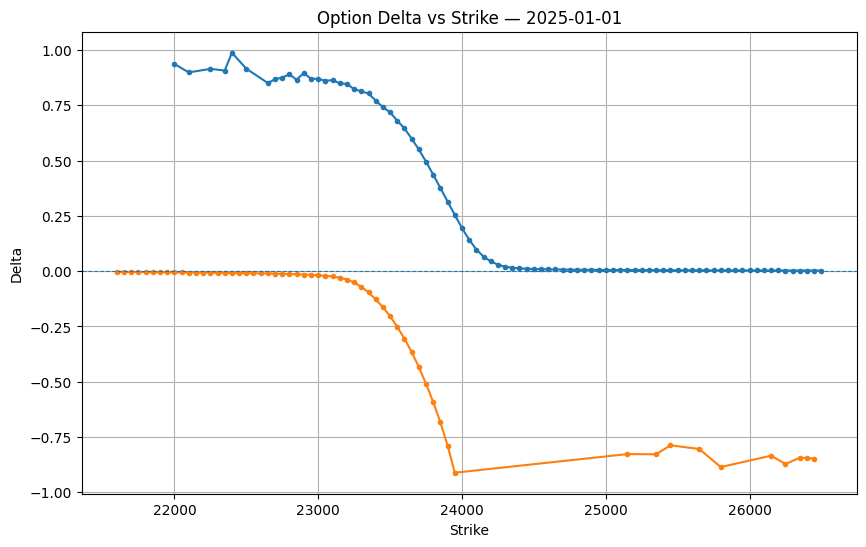

In [19]:
dts = df_with_greeks['date'].unique()
sensi_list = ["delta", "gamma", "vega", "theta", "rho","vanna","charm", "vomma", "speed", "zomma","color", "veta", "ultima", "dual_delta", "dual_gamma"]
sensi = 'delta'

df = df_with_greeks[(df_with_greeks['date'] == dts[0])] 
plt.figure(figsize=(10, 6))

# for dt in df['days_to_exp'].unique():
for dt in [1]:
    for opt in ['CE', 'PE']:
        temp = df[(df['option_type'] == opt) & (df['days_to_exp'] == dt)].sort_values('strike')

        plt.plot(temp['strike'],temp[sensi],marker='.',label=opt)

plt.axhline(0, linestyle='--', linewidth=0.8)
plt.xlabel('Strike')
plt.ylabel('Delta')
plt.title(f'Option Delta vs Strike — {dts[0]}')
# plt.legend()
plt.grid(True)
plt.show()


In [29]:
date_dd = widgets.Dropdown(
    options=sorted(df_with_greeks['date'].unique()),
    description='Date:'
)
sensi_dd = widgets.Dropdown(options=sensi_list, value='delta', description='Greek:')
ttm_dd = widgets.Dropdown(description='Days to maturity:')
opt_dd = widgets.Dropdown(options = [['CE'],['PE'],['CE', 'PE']], value= ['CE', 'PE'], description='Days to maturity:')

def update_ttm(*args):
    dates = df_with_greeks[df_with_greeks['date'] == date_dd.value]
    ttm_dd.options = sorted(dates['days_to_exp'].unique())
    if len(ttm_dd.options):
        ttm_dd.value = ttm_dd.options[0]

date_dd.observe(update_ttm, names='value')
update_ttm()

def plot_greek(date, sensi, dtm, instr):
    df = df_with_greeks[df_with_greeks['date'] == date]

    plt.figure(figsize=(10, 6))
    for opt in instr:
        temp = df[(df['option_type'] == opt) & (df['days_to_exp'] == dtm)].sort_values('strike')
        plt.plot(temp['strike'], temp[sensi], marker='.', label=opt)

    plt.axhline(0, linestyle='--', linewidth=0.8)
    plt.xlabel('Strike')
    plt.ylabel(sensi)
    plt.title(f'{sensi.capitalize()} vs Strike — {date}, DTM={dtm}')
    plt.legend()
    plt.grid(True)
    plt.show()

widgets.interactive(plot_greek, date=date_dd, sensi=sensi_dd, dtm=ttm_dd, instr = opt_dd)

interactive(children=(Dropdown(description='Date:', options=('2025-01-01', '2025-01-02', '2025-01-03', '2025-0…

In [ ]:
def plot_surface(date, sensi):
    df = df_with_greeks[df_with_greeks['date'] == date]

    fig = plt.figure(figsize=(10, 7))
    ax = fig.add_subplot(111, projection='3d')

    for opt in ['CE', 'PE']:
        temp = df[df['option_type'] == opt]

        surf = temp.pivot_table(
            index='days_to_exp',
            columns='strike',
            values=sensi,
            aggfunc='mean'
        ).sort_index().sort_index(axis=1)

        X, Y = np.meshgrid(surf.columns, surf.index)
        Z = surf.to_numpy(dtype=float)

        ax.plot_surface(X, Y, Z, alpha=0.7)

    ax.set_xlabel('Strike')
    ax.set_ylabel('Days to Maturity')
    ax.set_zlabel(sensi)
    ax.set_title(f'{sensi.capitalize()} Surface — {date}')

    plt.show()

In [ ]:
date_dd = widgets.Dropdown(
    options=sorted(df_with_greeks['date'].unique()),
    description='Date:'
)
sensi_dd = widgets.Dropdown(options=sensi_list, value='delta', description='Greek:')
ttm_dd = widgets.Dropdown(description='Days to maturity:')
opt_dd = widgets.Dropdown(options = [['CE'],['PE'],['CE', 'PE']], value= ['CE', 'PE'], description='Days to maturity:')

widgets.interactive(plot_greek, date=date_dd, sensi=sensi_dd, dtm=ttm_dd, instr = opt_dd)

surface_btn = widgets.Button(description='Plot Surface')
out = widgets.Output()

def on_surface_click(b):
    with out:
        out.clear_output(wait=True)
        plot_surface(date_dd.value, sensi_dd.value)

surface_btn.on_click(on_surface_click)
display(surface_btn, out)

Button(description='Plot Surface', style=ButtonStyle())

Output()

In [32]:
def plot_surface(date, sensi, instr):
    df = df_with_greeks[df_with_greeks['date'] == date]

    fig = plt.figure(figsize=(10, 7))
    ax = fig.add_subplot(111, projection='3d')

    for opt in instr:
        temp = df[df['option_type'] == opt]

        surf = temp.pivot_table(
            index='days_to_exp',
            columns='strike',
            values=sensi,
            aggfunc='mean'
        ).sort_index().sort_index(axis=1)

        X, Y = np.meshgrid(surf.columns, surf.index)
        Z = surf.to_numpy(dtype=float)

        ax.plot_surface(X, Y, Z, alpha=0.7)

    ax.set_xlabel('Strike')
    ax.set_ylabel('Days to Maturity')
    ax.set_zlabel(sensi)
    ax.set_title(f'{sensi.capitalize()} Surface — {date}')
    plt.show()


surface_btn = widgets.Button(description='Plot Surface')
out = widgets.Output()

def on_surface_click(b):
    with out:
        out.clear_output(wait=True)
        plot_surface(date_dd.value, sensi_dd.value, opt_dd.value)

surface_btn.on_click(on_surface_click)
display(widgets.HBox([date_dd, sensi_dd, opt_dd]), surface_btn, out)
# display(surface_btn, out)

Button(description='Plot Surface', style=ButtonStyle())

Output()

### Extend to work with the synthetic series of sensitivities


\[
d_1=\frac{\ln(S/K)+(r+\frac12\sigma^2)T}{\sigma\sqrt T},
\qquad d_2=d_1-\sigma\sqrt T
\]

\[
\Delta=N(d_1),\qquad
\Gamma=\frac{\phi(d_1)}{S\sigma\sqrt T},
\qquad
\text{Vega}=S\phi(d_1)\sqrt T
\]



In [ ]:
from scipy.stats import norm

def generate_synthetic_greeks(
    S_range=np.arange(22000, 26001, 200), # Select the S from the actuals
    K_range=np.arange(22000, 26001, 200), # Select K which are upper and lower for a given date selected
    sigma_range=np.arange(0.08, 0.201, 0.02),
    r_range=np.array([0.05, 0.06, 0.07]), # select from the table the actual and 1% on both side
    T_range=np.array([1/365, 7/365, 14/365, 30/365, 60/365]), # all the days to maturity from the table
    option_types=('CE', 'PE'),
    q=0.0
):
    df = pd.MultiIndex.from_product(
        [S_range, K_range, sigma_range, r_range, T_range, option_types],
        names=['spot', 'strike', 'implied_volatility', 'r',
               'ttm', 'option_type']
    ).to_frame(index=False)

    S = df['spot'].to_numpy(dtype=float)
    K = df['strike'].to_numpy(dtype=float)
    vol = df['implied_volatility'].to_numpy(dtype=float)
    r = df['r'].to_numpy(dtype=float)
    T = df['ttm'].to_numpy(dtype=float)
    is_call = df['option_type'].eq('CE').to_numpy()

    sqrtT = np.sqrt(T)
    d1 = (np.log(S/K) + (r - q + 0.5*vol**2)*T) / (vol*sqrtT)
    d2 = d1 - vol*sqrtT
    pdf = norm.pdf(d1)
    disc_q = np.exp(-q*T)
    disc_r = np.exp(-r*T)

    # Price and standard analytical Greeks
    call = disc_q*S*norm.cdf(d1) - disc_r*K*norm.cdf(d2)
    put = disc_r*K*norm.cdf(-d2) - disc_q*S*norm.cdf(-d1)

    df['model_price'] = np.where(is_call, call, put)
    df['delta'] = disc_q * np.where(is_call, norm.cdf(d1), norm.cdf(d1) - 1)
    df['gamma'] = disc_q * pdf / (S*vol*sqrtT)
    df['vega'] = S*disc_q*pdf*sqrtT

    df['theta'] = (
        -S*disc_q*pdf*vol/(2*sqrtT)
        - np.where(
            is_call,
            r*K*disc_r*norm.cdf(d2),
            -r*K*disc_r*norm.cdf(-d2)
        )
        + np.where(
            is_call,
            q*S*disc_q*norm.cdf(d1),
            -q*S*disc_q*norm.cdf(-d1)
        )
    ) / 365.0  # calendar-day theta

    df['rho'] = (
        np.where(
            is_call, K*T*disc_r*norm.cdf(d2),
            -K*T*disc_r*norm.cdf(-d2)
        ) / 100.0
    )  

    def price(s, v, t):
        s = np.maximum(s, 1e-8)
        v = np.maximum(v, 1e-8)
        t = np.maximum(t, 1e-10)
        d_1 = (np.log(s/K) + (r-q+0.5*v**2)*t)/(v*np.sqrt(t))
        d_2 = d_1 - v*np.sqrt(t)
        c = disc_q*s*norm.cdf(d_1) - disc_r*K*norm.cdf(d_2)
        p = disc_r*K*norm.cdf(-d_2) - disc_q*s*norm.cdf(-d_1)
        return np.where(is_call, c, p)

    hs = np.maximum(S*1e-4, 0.01)
    hv = 1e-4
    ht = np.minimum(T*1e-3, 1e-5)

    p0 = price(S, vol, T)
    psu, psd = price(S+hs, vol, T), price(S-hs, vol, T)
    pvu, pvd = price(S, vol+hv, T), price(S, vol-hv, T)
    ptu, ptd = price(S, vol, T+ht), price(S, vol, T-ht)

    # Cross / higher derivatives
    df['vanna'] = (
        price(S+hs, vol+hv, T) - price(S+hs, vol-hv, T)
        - price(S-hs, vol+hv, T) + price(S-hs, vol-hv, T)
    ) / (4*hs*hv)

    df['vomma'] = (pvu - 2*p0 + pvd) / hv**2
    df['speed'] = (psu - 2*p0 + psd) / hs**2
    df['zomma'] = (
        (price(S+hs, vol, T) - 2*p0 + price(S-hs, vol, T))
        / hs**2
    )
    # Zomma = derivative of Gamma with respect to volatility
    gamma_up = np.exp(-q*T)*norm.pdf(
        (np.log(S/K)+(r-q+0.5*(vol+hv)**2)*T)
        / ((vol+hv)*sqrtT)
    )/(S*(vol+hv)*sqrtT)
    gamma_dn = np.exp(-q*T)*norm.pdf(
        (np.log(S/K)+(r-q+0.5*(vol-hv)**2)*T)
        / ((vol-hv)*sqrtT)
    )/(S*(vol-hv)*sqrtT)
    df['zomma'] = (gamma_up - gamma_dn)/(2*hv)

    df['moneyness'] = S/K
    df['days_to_exp'] = T*365

    return df


synthetic_df_with_greeks = generate_synthetic_greeks()

### Generate the plot comparing synthetic to actuals

In [43]:
date_dd = widgets.Dropdown(
    options=sorted(synthetic_df_with_greeks[synthetic_df_with_greeks['spot'] == 22000]['date'].unique()),
    description='Date:'
)
sensi_dd = widgets.Dropdown(options=sensi_list, value='delta', description='Greek:')
ttm_dd = widgets.Dropdown(description='Days to maturity:')
opt_dd = widgets.Dropdown(options = [['CE'],['PE'],['CE', 'PE']], value= ['CE', 'PE'], description='Days to maturity:')

def update_ttm(*args):
    dates = synthetic_df_with_greeks[synthetic_df_with_greeks['spot'] == 22000][synthetic_df_with_greeks[synthetic_df_with_greeks['spot'] == 22000]['date'] == date_dd.value]
    ttm_dd.options = sorted(dates['days_to_exp'].unique())
    if len(ttm_dd.options):
        ttm_dd.value = ttm_dd.options[0]

date_dd.observe(update_ttm, names='value')
update_ttm()

def plot_greek(date, sensi, dtm, instr):
    df = synthetic_df_with_greeks[synthetic_df_with_greeks['spot'] == 22000][synthetic_df_with_greeks[synthetic_df_with_greeks['spot'] == 22000]['date'] == date]

    plt.figure(figsize=(10, 6))
    for opt in instr:
        temp = df[(df['option_type'] == opt) & (df['days_to_exp'] == dtm)].sort_values('strike')
        plt.plot(temp['strike'], temp[sensi], marker='.', label=opt)

    plt.axhline(0, linestyle='--', linewidth=0.8)
    plt.xlabel('Strike')
    plt.ylabel(sensi)
    plt.title(f'{sensi.capitalize()} vs Strike — {date}, DTM={dtm}')
    plt.legend()
    plt.grid(True)
    plt.show()

widgets.interactive(plot_greek, date=date_dd, sensi=sensi_dd, dtm=ttm_dd, instr = opt_dd)

KeyError: 'date'

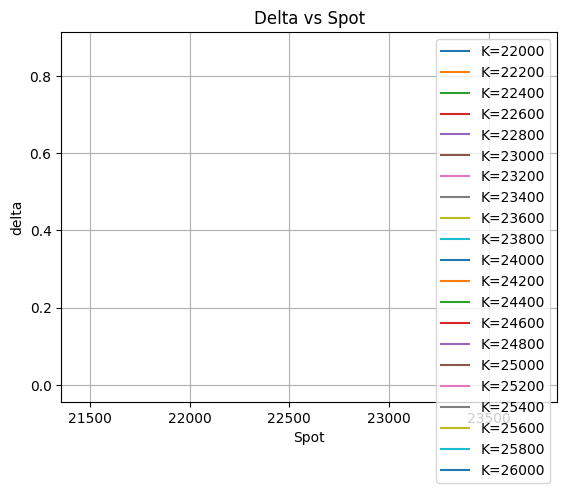

In [42]:
plot_synthetic_2d(synthetic_df_with_greeks[synthetic_df_with_greeks['spot'] == synthetic_df_with_greeks['spot'].unique()[3]], sensi='delta')
# plot_synthetic_surface(synthetic_df_with_greeks, sensi='gamma')

In [40]:
synthetic_df_with_greeks[synthetic_df_with_greeks['spot'] == 22000]

,spot,strike,implied_volatility,r,ttm,option_type,model_price,delta,gamma,vega,theta,rho,vanna,vomma,speed,zomma,moneyness,days_to_exp
0,22000,22000,0.08,0.05,0.002740,CE,38.275469,0.513883,4.327935e-03,459.116842,-19.908120,0.308689,-0.152555,6.116716,4.327730e-03,-0.054042,1.000000,1.0
1,22000,22000,0.08,0.05,0.002740,PE,35.261977,-0.486117,4.327935e-03,459.116842,-16.894834,-0.293968,-0.152555,6.116716,4.327730e-03,-0.054042,1.000000,1.0
2,22000,22000,0.08,0.05,0.019178,CE,108.095210,0.536688,1.629871e-03,1210.301866,-8.518618,2.243650,-0.402270,112.872112,1.629860e-03,-0.020221,1.000000,7.0
3,22000,22000,0.08,0.05,0.019178,PE,87.009431,-0.463312,1.629871e-03,1210.301866,-5.507808,-1.971484,-0.402270,112.872658,1.629860e-03,-0.020221,1.000000,7.0
4,22000,22000,0.08,0.05,0.038356,CE,159.482307,0.551811,1.147616e-03,1704.382510,-6.510810,4.595207,-0.566501,317.899321,1.147612e-03,-0.014131,1.000000,14.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4405,22000,26000,0.20,0.07,0.038356,PE,3930.288162,-0.999985,7.538903e-08,0.279910,4.970870,-9.945739,0.001369,24.644760,7.538959e-08,0.000006,0.846154,14.0
4406,22000,26000,0.20,0.07,0.082192,CE,0.995354,0.002681,6.552929e-06,52.136182,-0.184907,0.047655,0.117454,2062.756954,6.552940e-06,0.000227,0.846154,30.0
4407,22000,26000,0.20,0.07,0.082192,PE,3851.835814,-0.997319,6.552929e-06,52.136182,4.772789,-21.199611,0.117454,2062.756539,6.552940e-06,0.000227,0.846154,30.0
4408,22000,26000,0.20,0.07,0.164384,CE,20.313114,0.030211,3.836389e-05,610.458770,-1.141003,1.059183,0.670288,11226.346237,3.836390e-05,0.000514,0.846154,60.0


3. Apply the Taylor approximation
For each scenario, use the Greeks from the ATM base point:
\[
\begin{aligned}
\Delta P \approx {}&
\Delta\,\Delta S+\frac12\Gamma(\Delta S)^2
+\mathrm{Vega}\,\Delta\sigma\\
&+\frac12\mathrm{Vomma}(\Delta\sigma)^2
+\mathrm{Vanna}\,\Delta S\Delta\sigma
+\rho\,\Delta r.
\end{aligned}
\]

In [ ]:
def apply_taylor(grid):
    grid = grid.copy()
    dS = grid['S'] - grid['S0']

    grid['approx_pnl'] = (
        grid['delta'] * dS
        + 0.5 * grid['gamma'] * dS**2
        + grid['vega'] * grid['dvol']
        + 0.5 * grid['vomma'] * grid['dvol']**2
        + grid['vanna'] * dS * grid['dvol']
        + grid['rho'] * grid['dr']
    )

    grid['approx_price'] = grid['base_price'] + grid['approx_pnl']
    return grid

grid = apply_taylor(grid)
grid['actual_pnl'] = grid['actual_price'] - grid['base_price']
grid['error'] = grid['actual_pnl'] - grid['approx_pnl']
grid['abs_error'] = grid['error'].abs()

## Illustration

In [14]:
import plotly.express as px
import ipywidgets as widgets
from IPython.display import display, clear_output

data = df_with_greeks.copy()
for col in ["date_dt", "exdate_dt", "expiry"]:
    if col in data.columns:
        data[col] = pd.to_datetime(data[col], errors="coerce")

numeric_cols = [
    "strike", "close", "ttm", "days_to_exp",
    "delta", "gamma", "vega", "theta", "rho",
    "vanna", "charm", "vomma", "speed", "zomma",
    "color", "veta", "ultima", "dual_delta", "dual_gamma",
]
for col in numeric_cols:
    if col in data.columns:
        data[col] = pd.to_numeric(data[col], errors="coerce")

# Find the available sensitivities
greeks = [c for c in numeric_cols if c in data.columns
          and c not in ["strike", "close", "ttm", "days_to_exp"]]

# Derive moneyness only if a forward/spot column is available
underlying_col = next(
    (c for c in ["forward", "futures_price", "spot", "underlying_price"]
     if c in data.columns),
    None
)

if underlying_col:
    data["moneyness"] = data["strike"] / data[underlying_col]
    data["log_moneyness"] = np.log(data["moneyness"])

greek_w = widgets.Dropdown(
    options=greeks, description="Greek:"
)
type_w = widgets.Dropdown(
    options=["All", "CE", "PE"], description="Option:"
)
plot_w = widgets.Dropdown(
    options=[
        ("Greek vs strike", "strike"),
        ("Greek vs expiry days", "days_to_exp"),
        ("Greek vs moneyness", "log_moneyness"),
        ("Strike-expiry heatmap", "heatmap"),
    ],
    description="Plot:"
)
date_w = widgets.Dropdown(
    options=["All"] + sorted(data["date"].dropna().astype(str).unique().tolist()),
    description="Date:"
)
out = widgets.Output()

def draw(greek, opt_type, plot_type, date):
    with out:
        clear_output(wait=True)
        d = data.copy()

        if opt_type != "All":
            d = d[d["option_type"] == opt_type]
        if date != "All":
            d = d[d["date"].astype(str) == date]

        if plot_type == "log_moneyness" and "log_moneyness" not in d:
            print("Add a historical spot or forward column to calculate moneyness.")
            return

        if plot_type == "heatmap":
            d = d.dropna(subset=["strike", "days_to_exp", greek])
            if d.empty:
                print("No valid data for this selection.")
                return

            z = d.pivot_table(
                index="days_to_exp",
                columns="strike",
                values=greek,
                aggfunc="median"
            ).sort_index()

            fig = px.imshow(
                z,
                aspect="auto",
                origin="lower",
                labels=dict(
                    x="Strike", y="Days to expiry", color=greek
                ),
                title=f"{greek} across strike and expiry"
            )
        else:
            d = d.dropna(subset=[plot_type, greek])
            if d.empty:
                print("No valid data for this selection.")
                return

            fig = px.scatter(
                d,
                x=plot_type,
                y=greek,
                color="option_type",
                hover_data=[
                    c for c in ["strike", "expiry", "close", "ttm"]
                    if c in d.columns
                ],
                title=f"{greek} vs {plot_type}",
                opacity=0.65,
            )

        fig.update_layout(template="plotly_white")
        fig.show()

def refresh(change=None):
    draw(greek_w.value, type_w.value, plot_w.value, date_w.value)

for w in [greek_w, type_w, plot_w, date_w]:
    w.observe(refresh, names="value")

display(widgets.HBox([greek_w, type_w]))
display(widgets.HBox([plot_w, date_w]))
display(out)
refresh()


Output()